# Notebook 11: Sex × task mixed model on projection scores

Section 3.4 currently ranks tasks by how strongly each expresses the comp_1 and comp_4 signatures, and is explicitly descriptive: no sex variable enters it. This notebook adds the inferential version — a linear mixed model with a sex × task interaction on the per-task projection scores, plus per-task sex effect sizes with bootstrap confidence intervals.

**Read this before running it.** The manuscript's state/trait dissociation rests on comp_1 being task-selective and comp_4 being task-invariant, and the current text hedges that claim consistently through 4.1 and 4.3 because it was never tested. A significant sex × task interaction turns the hedge into a finding. A non-significant one means the hedge must *stay* — and the descriptive ranking in 3.4 must not be read as evidence of selectivity, because a formal test will have failed to find it. Either outcome constrains the Discussion more tightly than the present wording does, so decide with Mateo which framing you are committing to before the result is in hand rather than after.

**Model.** For each component separately:

`projection ~ sex * task + (1 | participant)`

Projection scores are z-scored within task by default, which puts every task on a common scale and makes the interaction a test of whether the *standardised* sex difference varies across tasks. The raw-scale model is fitted as a sensitivity check. The interaction is tested by likelihood-ratio against the additive model, both fitted by ML.

**Per-task effect sizes** are rank-biserial correlations (positive = higher in females) with percentile bootstrap CIs, resampling participants within sex. These are reported as estimates with uncertainty, not as a second significance sweep — no per-task p-values, and no FDR pass that would invite reading them as 37 independent tests.

**Inputs:** `outputs/nmf_W.csv`, `outputs/nmf_H.csv`, `outputs/metadata.csv`, `data/eeg_features/BA*/2_emotiv_fft_values.csv`, `data/stimuli.csv`

**Outputs:** `outputs/task_projections_long.csv`, `outputs/mixed_model_results.csv`, `outputs/per_task_sex_effects.csv`, `outputs/sex_task_interaction.png`

## Setup

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy import stats
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import re
import time
import warnings
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(".").resolve().parent
DATA_DIR = PROJECT_ROOT / "data"
EEG_DIR = DATA_DIR / "eeg_features"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

COMPONENTS_OF_INTEREST = ["comp_1", "comp_4"]

FREQ_BANDS = ["Theta", "Alpha", "BetaL", "BetaH", "Gamma"]
CHANNELS = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1",
            "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]
POW_COLS = [f"POW.{ch}.{band}" for ch in CHANNELS for band in FREQ_BANDS]

SEX_COL = "Gender"
SEX_ORDER = ["F", "M"]          # positive effect = higher in females
Z_SCORE_WITHIN_TASK = True      # primary specification
N_BOOTSTRAP = 2000
RANDOM_SEED = 42
MIN_PARTICIPANTS_PER_TASK = 10

rng = np.random.default_rng(RANDOM_SEED)
report = []
def log(msg=""):
    print(msg); report.append(str(msg))

## Rebuild the per-task projection scores

This repeats the projection step from Notebook 06 exactly — component signature averaged across the five categories, per-task median spectral vectors transformed with the same log/winsorise/min-max pipeline, then projected — and saves the result in long format so it does not have to be recomputed again.

In [2]:
W = pd.read_csv(OUTPUT_DIR / "nmf_W.csv", index_col="participant_id")
H = pd.read_csv(OUTPUT_DIR / "nmf_H.csv", index_col=0)
metadata = pd.read_csv(OUTPUT_DIR / "metadata.csv").set_index("participant_id").reindex(W.index)
stimuli = pd.read_csv(DATA_DIR / "stimuli.csv")
TASKS = stimuli["original_stimuli_name"].astype(str).tolist()
sex = metadata[SEX_COL]

assert (W.index == metadata.index).all()
log(f"Participants: {len(W)} | tasks: {len(TASKS)} | sex: {dict(sex.value_counts())}")

def parse_feature_name(name):
    cat, pow_part = name.split("__", 1)
    _, ch, band = pow_part.split(".")
    return cat, ch, band

def component_signature(comp):
    row = H.loc[comp]
    recs = [{"channel": parse_feature_name(f)[1], "band": parse_feature_name(f)[2], "loading": v}
            for f, v in row.items()]
    sig = pd.DataFrame(recs).groupby(["channel", "band"])["loading"].mean()
    return np.array([sig.loc[(ch, b)] for ch in CHANNELS for b in FREQ_BANDS])

signatures = {c: component_signature(c) for c in COMPONENTS_OF_INTEREST}

def ba_sort_key(p):
    m = re.match(r"BA(\d+)", p.name)
    return int(m.group(1)) if m else 99999

folders = sorted([p for p in EEG_DIR.iterdir() if p.is_dir() and re.match(r"BA\d+", p.name)],
                 key=ba_sort_key)

task_vectors = {t: {} for t in TASKS}
for folder in folders:
    pid = folder.name
    if pid not in W.index:
        continue
    fpath = folder / "2_emotiv_fft_values.csv"
    if not fpath.exists():
        continue
    df = pd.read_csv(fpath)
    if "task_name" not in df.columns or any(c not in df.columns for c in POW_COLS):
        continue
    for task in TASKS:
        sub = df[df["task_name"] == task]
        if len(sub):
            task_vectors[task][pid] = sub[POW_COLS].median().values

def transform_matrix(M):
    Ml = np.log1p(M)
    lo = np.nanpercentile(Ml, 2.5, axis=0)
    hi = np.nanpercentile(Ml, 97.5, axis=0)
    Ml = np.clip(Ml, lo, hi)
    mn, mx = np.nanmin(Ml, axis=0), np.nanmax(Ml, axis=0)
    rng_ = np.where((mx - mn) == 0, 1, (mx - mn))
    return (Ml - mn) / rng_

rows = []
dropped = []
for task in TASKS:
    pdata = task_vectors[task]
    pids = [p for p in W.index if p in pdata]
    if len(pids) < MIN_PARTICIPANTS_PER_TASK:
        dropped.append((task, len(pids)))
        continue
    Mt = transform_matrix(np.vstack([pdata[p] for p in pids]))
    for comp in COMPONENTS_OF_INTEREST:
        proj = Mt @ signatures[comp]
        for pid, v in zip(pids, proj):
            rows.append({"participant": pid, "task": task, "component": comp,
                         "projection": float(v), "sex": sex.loc[pid],
                         "overall_loading": float(W.loc[pid, comp])})

long = pd.DataFrame(rows).dropna(subset=["sex"])
long.to_csv(OUTPUT_DIR / "task_projections_long.csv", index=False)
log(f"\nProjection records: {len(long)} "
    f"({long['task'].nunique()} tasks × {long['participant'].nunique()} participants × "
    f"{len(COMPONENTS_OF_INTEREST)} components)")
if dropped:
    log(f"Tasks dropped for insufficient coverage: {dropped}")

Participants: 86 | tasks: 37 | sex: {'M': 44, 'F': 42}

Projection records: 6336 (37 tasks × 86 participants × 2 components)


## Fit the mixed models

`statsmodels.MixedLM` with a random intercept per participant. The interaction is tested by likelihood-ratio against the additive model, with both fitted by maximum likelihood — REML likelihoods are not comparable across models with different fixed-effect structures, which is a common and silent error here.

Degrees of freedom for the LRT equal the number of extra interaction terms, i.e. (number of tasks − 1).

In [3]:
long["z"] = long.groupby(["component", "task"])["projection"].transform(
    lambda s: (s - s.mean()) / (s.std(ddof=1) if s.std(ddof=1) > 0 else 1.0))
long["sex_f"] = pd.Categorical(long["sex"], categories=SEX_ORDER[::-1])  # M as reference

response = "z" if Z_SCORE_WITHIN_TASK else "projection"
log(f"Response variable: {response} "
    f"({'within-task z-scored (primary)' if Z_SCORE_WITHIN_TASK else 'raw projection'})")

model_rows = []
fitted = {}
for comp in COMPONENTS_OF_INTEREST:
    d = long[long["component"] == comp].copy()
    t0 = time.time()
    full = smf.mixedlm(f"{response} ~ C(task) * sex_f", d, groups=d["participant"]).fit(reml=False)
    add  = smf.mixedlm(f"{response} ~ C(task) + sex_f", d, groups=d["participant"]).fit(reml=False)
    lr = 2 * (full.llf - add.llf)
    df_diff = int(d["task"].nunique() - 1)
    p_lrt = float(stats.chi2.sf(lr, df_diff))
    fitted[comp] = {"full": full, "additive": add}

    main_terms = [t for t in add.params.index if t.startswith("sex_f")]
    main_beta = float(add.params[main_terms[0]]) if main_terms else np.nan
    main_p = float(add.pvalues[main_terms[0]]) if main_terms else np.nan

    model_rows.append({
        "component": comp, "response": response, "n_obs": len(d),
        "n_participants": d["participant"].nunique(), "n_tasks": d["task"].nunique(),
        "sex_main_beta": main_beta, "sex_main_p": main_p,
        "interaction_LR_chi2": float(lr), "interaction_df": df_diff, "interaction_p": p_lrt,
        "converged_full": bool(full.converged), "converged_additive": bool(add.converged),
        "seconds": round(time.time() - t0, 1),
    })
    log(f"\n=== {comp} ===")
    log(f"  sex main effect (additive model): β = {main_beta:+.4f}, p = {main_p:.4g}")
    log(f"  sex × task interaction: χ²({df_diff}) = {lr:.2f}, p = {p_lrt:.4g}")
    log(f"  converged: full = {full.converged}, additive = {add.converged}")

model_df = pd.DataFrame(model_rows)
model_df.to_csv(OUTPUT_DIR / "mixed_model_results.csv", index=False)

if not model_df[["converged_full", "converged_additive"]].all().all():
    log("\n[CHECK] At least one model failed to converge. The corresponding LRT is not")
    log("        interpretable — do not report it without resolving the convergence failure.")

Response variable: z (within-task z-scored (primary))

=== comp_1 ===
  sex main effect (additive model): β = +0.1963, p = 0.2817
  sex × task interaction: χ²(36) = 38.91, p = 0.34
  converged: full = True, additive = True

=== comp_4 ===
  sex main effect (additive model): β = +0.0810, p = 0.6618
  sex × task interaction: χ²(36) = 44.16, p = 0.165
  converged: full = True, additive = True


## Sensitivity check on the raw scale

Same models on untransformed projection scores. Within-task z-scoring removes between-task differences in both mean and variance; if the interaction conclusion flips between the two specifications, it is being driven by heteroscedasticity across tasks rather than by a genuine difference in the sex effect, and that has to be stated.

In [4]:
alt_response = "projection" if Z_SCORE_WITHIN_TASK else "z"
sens_rows = []
for comp in COMPONENTS_OF_INTEREST:
    d = long[long["component"] == comp].copy()
    full = smf.mixedlm(f"{alt_response} ~ C(task) * sex_f", d, groups=d["participant"]).fit(reml=False)
    add  = smf.mixedlm(f"{alt_response} ~ C(task) + sex_f", d, groups=d["participant"]).fit(reml=False)
    lr = 2 * (full.llf - add.llf)
    df_diff = int(d["task"].nunique() - 1)
    sens_rows.append({"component": comp, "response": alt_response,
                      "interaction_LR_chi2": float(lr), "interaction_df": df_diff,
                      "interaction_p": float(stats.chi2.sf(lr, df_diff)),
                      "converged": bool(full.converged and add.converged)})
sens_df = pd.DataFrame(sens_rows)
log(f"Sensitivity check on '{alt_response}':")
log(sens_df.round(4).to_string(index=False))

for comp in COMPONENTS_OF_INTEREST:
    p_main = model_df.loc[model_df["component"] == comp, "interaction_p"].values[0]
    p_alt = sens_df.loc[sens_df["component"] == comp, "interaction_p"].values[0]
    if (p_main < 0.05) != (p_alt < 0.05):
        log(f"\n[CHECK] {comp}: the two specifications disagree (p = {p_main:.4g} vs {p_alt:.4g}).")
        log("        Report both and attribute the difference to between-task variance scaling.")

Sensitivity check on 'projection':
component   response  interaction_LR_chi2  interaction_df  interaction_p  converged
   comp_1 projection              40.3850              36         0.2826       True
   comp_4 projection              45.7238              36         0.1285       True


## Per-task sex effect sizes with bootstrap CIs

In [5]:
def rank_biserial_fm(vals_f, vals_m):
    u, _ = stats.mannwhitneyu(vals_f, vals_m, alternative="two-sided")
    return 2.0 * u / (len(vals_f) * len(vals_m)) - 1.0

effect_rows = []
for comp in COMPONENTS_OF_INTEREST:
    d = long[long["component"] == comp]
    for task, sub in d.groupby("task"):
        f = sub.loc[sub["sex"] == SEX_ORDER[0], "projection"].values
        m = sub.loc[sub["sex"] == SEX_ORDER[1], "projection"].values
        if len(f) < 5 or len(m) < 5:
            continue
        r = rank_biserial_fm(f, m)
        boots = np.empty(N_BOOTSTRAP)
        for b in range(N_BOOTSTRAP):
            boots[b] = rank_biserial_fm(rng.choice(f, len(f), replace=True),
                                        rng.choice(m, len(m), replace=True))
        lo, hi = np.percentile(boots, [2.5, 97.5])
        effect_rows.append({"component": comp, "task": task, "n_female": len(f), "n_male": len(m),
                            "rank_biserial": r, "ci_lo": float(lo), "ci_hi": float(hi),
                            "ci_excludes_zero": bool(lo > 0 or hi < 0),
                            "direction": "higher in females" if r > 0 else "higher in males"})

effects = pd.DataFrame(effect_rows)
effects.to_csv(OUTPUT_DIR / "per_task_sex_effects.csv", index=False)

for comp in COMPONENTS_OF_INTEREST:
    sub = effects[effects["component"] == comp].sort_values("rank_biserial", ascending=False)
    n_excl = int(sub["ci_excludes_zero"].sum())
    log(f"\n=== {comp}: per-task sex effects ({len(sub)} tasks) ===")
    log(f"  effect range: {sub['rank_biserial'].min():+.3f} to {sub['rank_biserial'].max():+.3f}")
    log(f"  tasks whose 95% CI excludes zero: {n_excl}/{len(sub)}")
    log(f"  tasks higher in females: {int((sub['rank_biserial'] > 0).sum())}, "
        f"higher in males: {int((sub['rank_biserial'] < 0).sum())}")
    log(sub.head(8)[["task", "rank_biserial", "ci_lo", "ci_hi", "ci_excludes_zero"]]
        .round(3).to_string(index=False))

log("\nThese CIs are uncorrected and are not 37 independent tests. Quote them as estimates")
log("with uncertainty. The inferential claim about whether the sex effect varies across tasks")
log("is the interaction LRT above, which is a single test per component.")


=== comp_1: per-task sex effects (37 tasks) ===
  effect range: -0.028 to +0.297
  tasks whose 95% CI excludes zero: 3/37
  tasks higher in females: 36, higher in males: 1
                task  rank_biserial  ci_lo  ci_hi  ci_excludes_zero
        gyrus_coord2          0.297  0.046  0.518              True
         gyrus_coord          0.256  0.017  0.487              True
              valdo1          0.241  0.001  0.491              True
    gyrus_right_open          0.240 -0.004  0.473             False
     gyrus_left_open          0.235 -0.017  0.459             False
     frontal3_recall          0.231 -0.009  0.472             False
parietal_next_in_seq          0.228 -0.014  0.463             False
     frontal2_recall          0.224 -0.011  0.465             False

=== comp_4: per-task sex effects (37 tasks) ===
  effect range: -0.116 to +0.218
  tasks whose 95% CI excludes zero: 0/37
  tasks higher in females: 29, higher in males: 8
                     task  rank_biserial  

## Figure

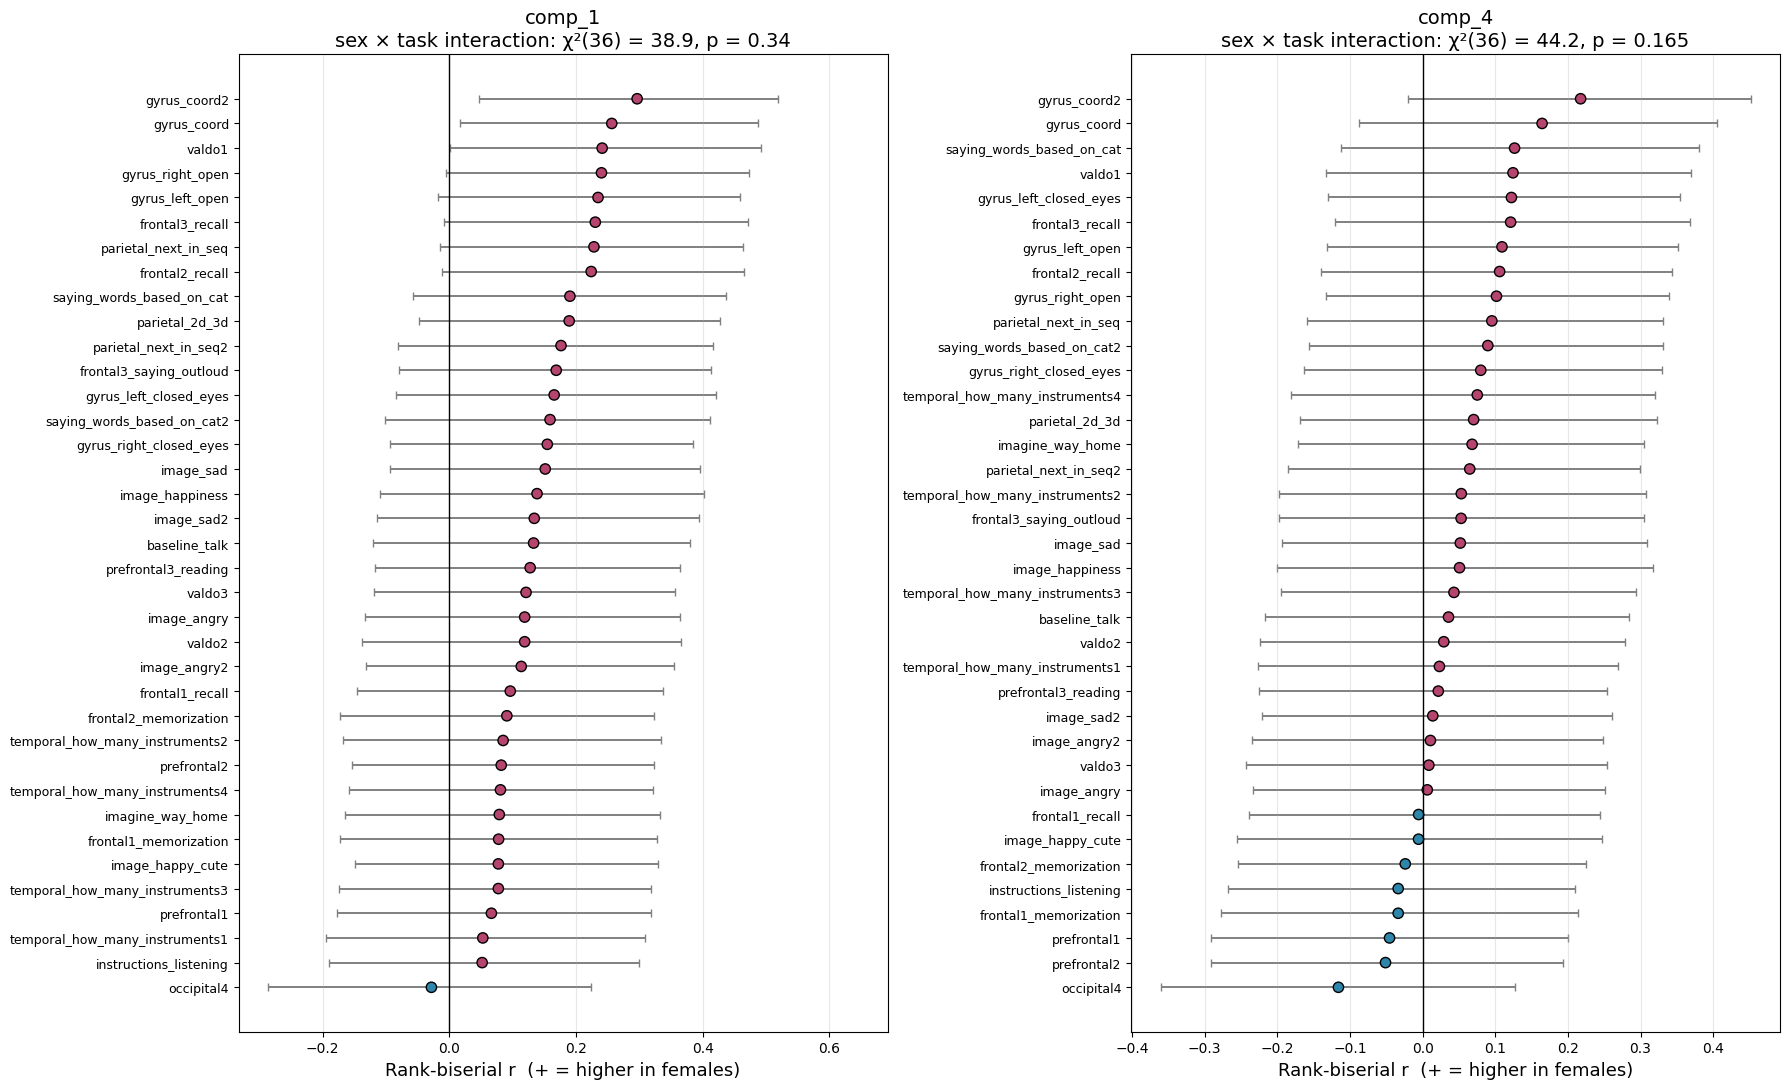

In [6]:
n_comp = len(COMPONENTS_OF_INTEREST)
fig, axes = plt.subplots(1, n_comp, figsize=(9 * n_comp, 11), squeeze=False)

for ax, comp in zip(axes[0], COMPONENTS_OF_INTEREST):
    sub = effects[effects["component"] == comp].sort_values("rank_biserial")
    y = np.arange(len(sub))
    colours = ["#B5446E" if r > 0 else "#2E86AB" for r in sub["rank_biserial"]]
    ax.errorbar(sub["rank_biserial"], y,
                xerr=[sub["rank_biserial"] - sub["ci_lo"], sub["ci_hi"] - sub["rank_biserial"]],
                fmt="none", ecolor="gray", elinewidth=1.4, capsize=3, zorder=1)
    ax.scatter(sub["rank_biserial"], y, c=colours, s=55, edgecolor="black", zorder=2)
    for yi, excl in zip(y, sub["ci_excludes_zero"]):
        if excl:
            ax.scatter(ax.get_xlim()[1], yi, marker="", s=0)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(sub["task"], fontsize=9)
    ax.set_xlabel("Rank-biserial r  (+ = higher in females)", fontsize=13)
    row = model_df[model_df["component"] == comp].iloc[0]
    ax.set_title(f"{comp}\nsex × task interaction: χ²({int(row['interaction_df'])}) = "
                 f"{row['interaction_LR_chi2']:.1f}, p = {row['interaction_p']:.3g}",
                 fontsize=14)
    ax.grid(alpha=0.3, axis="x")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sex_task_interaction.png", dpi=200, bbox_inches="tight")
plt.show()

## Verdict

In [7]:
log("\n" + "=" * 78)
log("SEX × TASK INTERACTION — VERDICT")
log("=" * 78)
for comp in COMPONENTS_OF_INTEREST:
    row = model_df[model_df["component"] == comp].iloc[0]
    sub = effects[effects["component"] == comp]
    log(f"\n{comp}: χ²({int(row['interaction_df'])}) = {row['interaction_LR_chi2']:.2f}, "
        f"p = {row['interaction_p']:.4g}; per-task r spans "
        f"{sub['rank_biserial'].min():+.3f} to {sub['rank_biserial'].max():+.3f}")

p1 = model_df.loc[model_df["component"] == "comp_1", "interaction_p"].values[0] \
     if "comp_1" in set(model_df["component"]) else np.nan
p4 = model_df.loc[model_df["component"] == "comp_4", "interaction_p"].values[0] \
     if "comp_4" in set(model_df["component"]) else np.nan

log("\nInterpretation against the state/trait framing:")
if p1 < 0.05 and p4 >= 0.05:
    log("  This is the pattern the manuscript predicts: the comp_1 sex effect varies across")
    log("  tasks (state-like), while the comp_4 effect does not (trait-like). The dissociation")
    log("  can now be stated as tested rather than hedged — but the hedging currently in 4.1")
    log("  and 4.3 must then be revised consistently, not left in place alongside the new claim.")
elif p1 >= 0.05 and p4 >= 0.05:
    log("  Neither component shows a task-varying sex effect. The descriptive ranking in 3.4")
    log("  therefore cannot be read as evidence of selectivity, and the existing hedging must")
    log("  stay exactly as it is. State the null interaction explicitly rather than omitting it;")
    log("  a formal test that was run and did not support the pattern has to be reported.")
elif p1 < 0.05 and p4 < 0.05:
    log("  Both components show task-varying sex effects. The state/trait contrast as currently")
    log("  drawn does not hold — comp_4 is not task-invariant. Section 4.2 needs rethinking with")
    log("  Mateo before anything is rewritten.")
else:
    log("  comp_4 varies across tasks while comp_1 does not — the reverse of the predicted")
    log("  pattern. Treat this as a finding that contradicts the current framing, not as an")
    log("  anomaly to be explained away.")

log("\nFiles saved:")
for f in ["task_projections_long.csv", "mixed_model_results.csv", "per_task_sex_effects.csv",
          "sex_task_interaction.png", "mixed_model_summary.txt"]:
    log(f"  {f}")
with open(OUTPUT_DIR / "mixed_model_summary.txt", "w", encoding="utf-8") as fh:
    fh.write("\n".join(report))


SEX × TASK INTERACTION — VERDICT

comp_1: χ²(36) = 38.91, p = 0.34; per-task r spans -0.028 to +0.297

comp_4: χ²(36) = 44.16, p = 0.165; per-task r spans -0.116 to +0.218

Interpretation against the state/trait framing:
  Neither component shows a task-varying sex effect. The descriptive ranking in 3.4
  therefore cannot be read as evidence of selectivity, and the existing hedging must
  stay exactly as it is. State the null interaction explicitly rather than omitting it;
  a formal test that was run and did not support the pattern has to be reported.

Files saved:
  task_projections_long.csv
  mixed_model_results.csv
  per_task_sex_effects.csv
  sex_task_interaction.png
  mixed_model_summary.txt
